# Brasileirao em numeros: analise e resultados

Notebook de leitura. O codigo de verdade vive em `src/brasileirao/` (testado); aqui ele so e
chamado, e os numeros vem dos arquivos que o pipeline grava em `reports/`.

**Quatro perguntas:**
1. Quanto vale o mando de campo e o que os portoes fechados de 2020 mostram?
2. Da para prever partidas melhor que o mercado de apostas?
3. O rebaixamento do Santos em 2023 foi azar?
4. Onde o Santos termina 2026?

In [1]:
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import poisson

from brasileirao import config, estilo
from brasileirao.dados import carregar

estilo.aplicar()
dados = carregar()           # confere o SHA-256 do snapshot e valida as regras da Serie A
p = dados.partidas
ler = lambda nome: json.loads((config.RELATORIOS / nome).read_text(encoding="utf-8"))
print(f"{len(p)} partidas, {p.temporada.min()}-{p.temporada.max()}")
p.groupby("temporada").size().to_frame("jogos").T

5618 partidas, 2012-2026


temporada,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
jogos,380,380,380,380,379,380,380,380,380,380,380,380,380,380,299


## 0. Os gols seguem uma Poisson? (a hipotese que sustenta o modelo)

O Dixon-Coles supoe gols ~ Poisson. Antes de usar, vale olhar: frequencia observada de cada
placar contra o que duas Poisson independentes (com as medias do campeonato) preveriam.

In [2]:
lam, mu = p.gols_mandante.mean(), p.gols_visitante.mean()
obs = pd.crosstab(p.gols_mandante.clip(upper=4), p.gols_visitante.clip(upper=4), normalize=True)
g = np.arange(5)
pc, pf = poisson.pmf(g, lam), poisson.pmf(g, mu)
pc[-1], pf[-1] = 1 - pc[:-1].sum(), 1 - pf[:-1].sum()
esp = pd.DataFrame(np.outer(pc, pf), index=obs.index, columns=obs.columns)
razao = (obs / esp).round(2)
print(f"media de gols: mandante {lam:.2f}, visitante {mu:.2f}")
razao.style.background_gradient(cmap="RdBu_r", vmin=0.7, vmax=1.3).format("{:.2f}")

media de gols: mandante 1.43, visitante 0.97


gols_visitante,0,1,2,3,4
gols_mandante,,,,,
0,0.94,0.92,0.93,1.03,1.19
1,1.10,1.02,1.04,0.81,0.98
2,0.93,1.13,1.10,0.89,0.75
3,1.03,0.92,1.02,1.00,1.75
4,0.83,0.87,0.98,1.07,0.90


Leitura da tabela (observado / previsto, 1.00 = perfeito): a Poisson e uma aproximacao boa para o
Brasileirao -- os placares comuns ficam dentro de +-10%. Os desvios maiores estao em placares raros
(4x3, 3x4...), com pouca amostra.

In [3]:
emp = (p.resultado == "D").mean()
emp_poisson = np.trace(np.outer(poisson.pmf(np.arange(11), lam), poisson.pmf(np.arange(11), mu)))
print(f"empates observados: {emp:.1%}  |  Poisson independente preve: {emp_poisson:.1%}")

from brasileirao.modelos.dixon_coles import DixonColes

hiper = ler("hiperparametros.json")["dixon_coles"]["melhor"]
dc = DixonColes(**hiper).ajustar(p)
print(f"rho do Dixon-Coles (ja descontada a forca de cada time): {dc.rho:+.3f}")
print(f"mando: gols do mandante x {np.exp(dc.mando):.2f}")

empates observados: 26.9%  |  Poisson independente preve: 26.8%
rho do Dixon-Coles (ja descontada a forca de cada time): -0.063
mando: gols do mandante x 1.40


Esta tabela mistura todos os times; a correcao `rho` do Dixon-Coles e estimada **depois** de
descontar a forca de cada um, entao as duas coisas nao se comparam direto. Resultado: `rho`
pequeno (~ -0,06). Ou seja, no Brasileirao a correcao de placares baixos e um ajuste fino, nao a
peca central do modelo -- quem carrega o modelo e ataque/defesa por clube + mando + peso temporal.

## 1. Mando de campo e o experimento natural de 2020

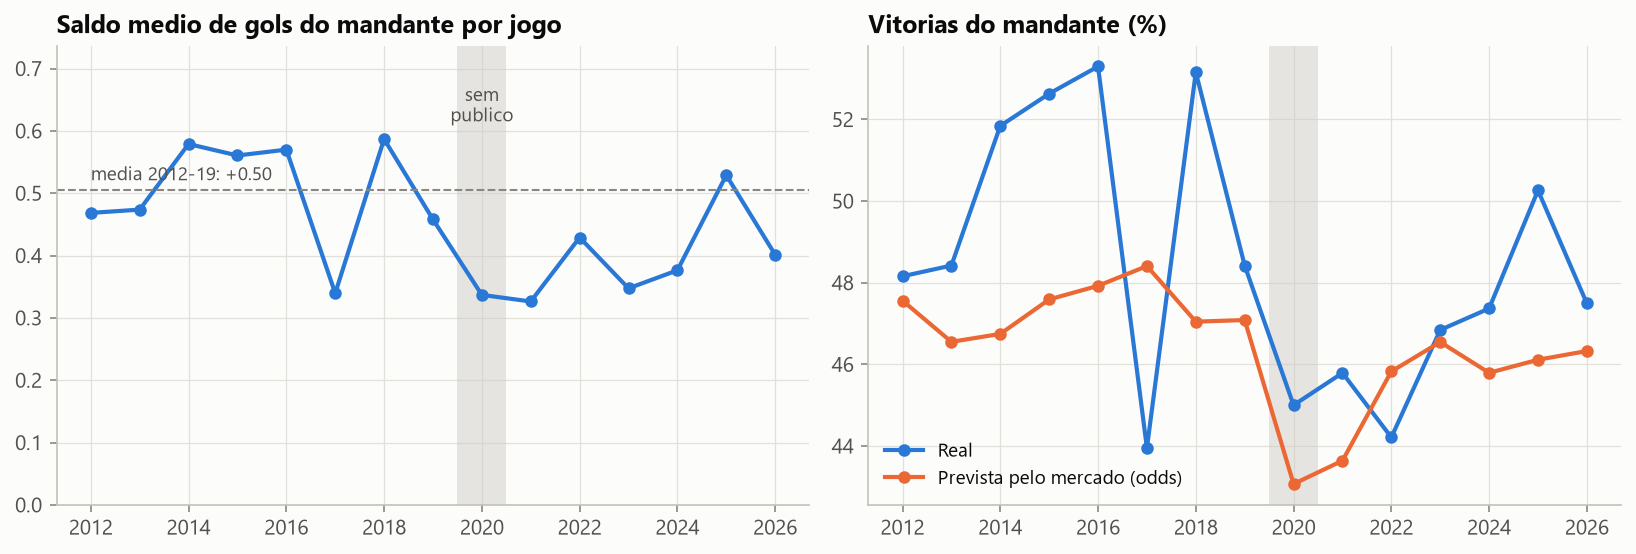

,valor
saldo_com_publico,0.504442
saldo_sem_publico,0.336842
diferenca,-0.1676
ic95,"[-0.3265088715124435, -0.008038503836095778]"
p_valor_permutacao,0.019
queda_relativa,-0.332248
temporadas_com_publico_tao_baixas_quanto_2020,[2017]
desvio_padrao_entre_temporadas_com_publico,0.085689
saldo_2022_2026,0.417262


In [4]:
m = ler("mando.json")
display(Image(config.FIGURAS / "mando_por_temporada.png"))
pd.Series(m["portoes_fechados"]).to_frame("valor")

- Sem publico, o saldo medio do mandante caiu de **+0,50 para +0,34 gol/jogo (-33%)**, IC95% do
  bootstrap inteiro abaixo de zero, p = 0,02 no teste de permutacao.
- **Mas**: 2017, com torcida, teve a mesma queda. O desvio entre temporadas (0,09) e grande, e
  uma temporada sem publico e uma amostra so. Conclusao honesta: *evidencia consistente com o
  efeito da torcida, nao prova.*
- O mercado precificou a mudanca ja em 2020 (P(mandante) media caiu de ~47% para 43%).

## 2. Modelo x mercado (walk-forward, 2017-2026)

In [5]:
met = ler("metricas.json")
display(pd.DataFrame(met["geral"]).T.round(4))
pd.DataFrame(met["comparacoes_rps"]).T.round(5)

,rps,log_loss,brier,acuracia
frequencia,0.2194,1.0580,0.6383,0.4724
elo,0.2078,1.0233,0.6140,0.4929
dixon_coles,0.2078,1.0239,0.6142,0.4915
media_dc_elo,0.2073,1.0218,0.6128,0.4931
mercado,0.2007,1.0006,0.5988,0.5109
mercado_shin,0.2006,1.0001,0.5984,0.5109


,diferenca,ic_inf,ic_sup,p_a_melhor
dixon_coles - frequencia,-0.01163,-0.01400,-0.00926,1.0000
dixon_coles - elo,-0.00001,-0.00114,0.00113,0.5066
media_dc_elo - dixon_coles,-0.00052,-0.00109,0.00005,0.9648
dixon_coles - mercado,0.00705,0.00513,0.00892,0.0000
mercado_shin - mercado,-0.00014,-0.00032,0.00004,0.9320


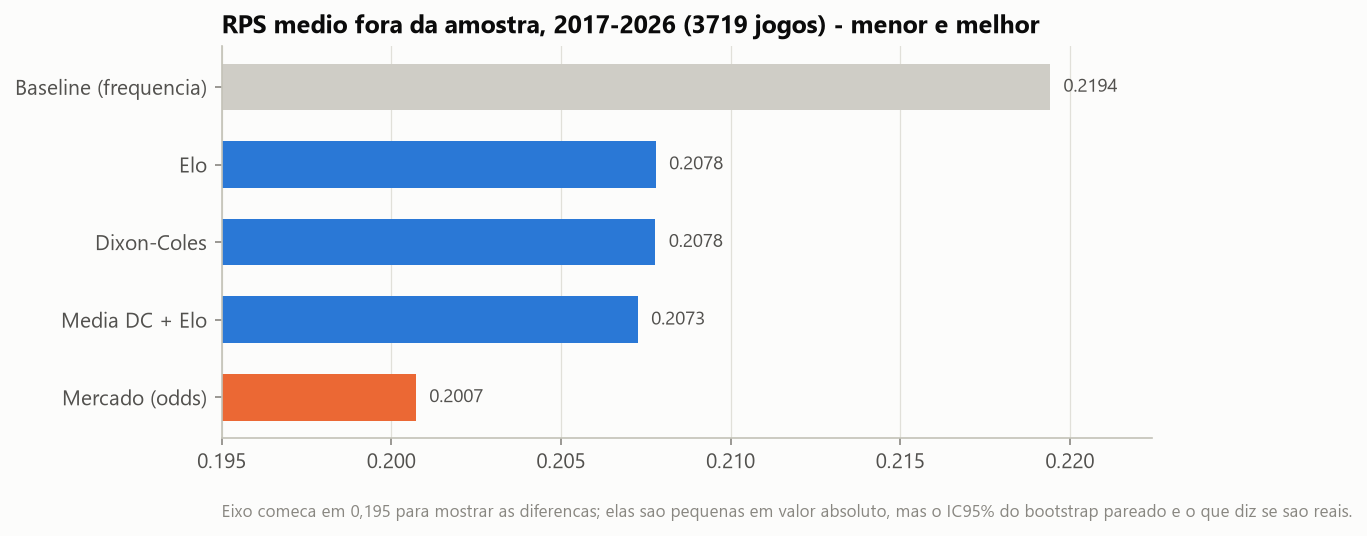

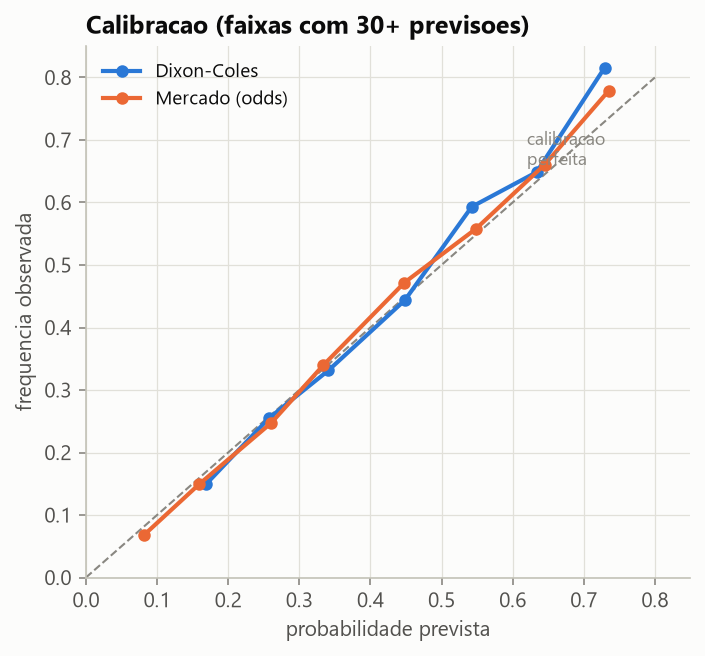

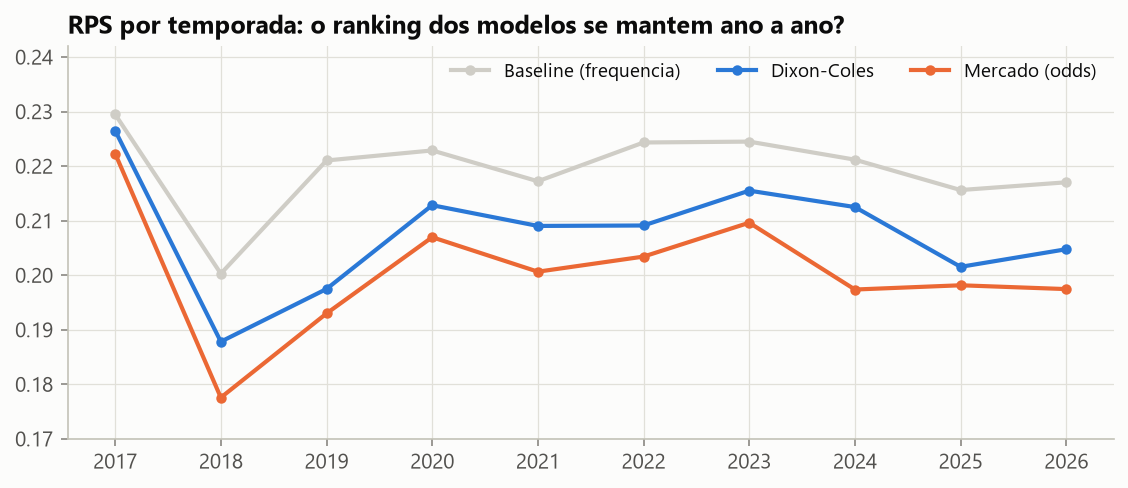

In [6]:
display(Image(config.FIGURAS / "rps_modelos.png"))
display(Image(config.FIGURAS / "calibracao.png"))
display(Image(config.FIGURAS / "rps_por_temporada.png"))

- Dixon-Coles e Elo empatam (IC da diferenca cruza o zero); a media dos dois e levemente melhor.
- Todos batem o baseline com folga e **nenhum bate o mercado** -- em nenhuma das 10 temporadas.
  O modelo captura ~62% do ganho que o mercado tem sobre o baseline usando *so placares*.
- Os dois sao bem calibrados: quando dizem 40%, acontece ~40% das vezes.

## 3. Santos 2023: azar ou desempenho?

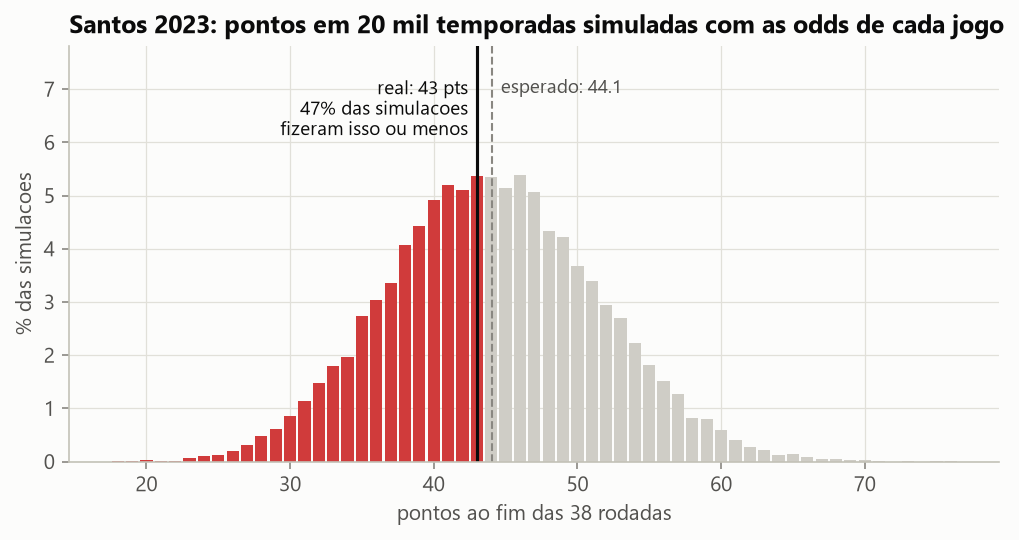

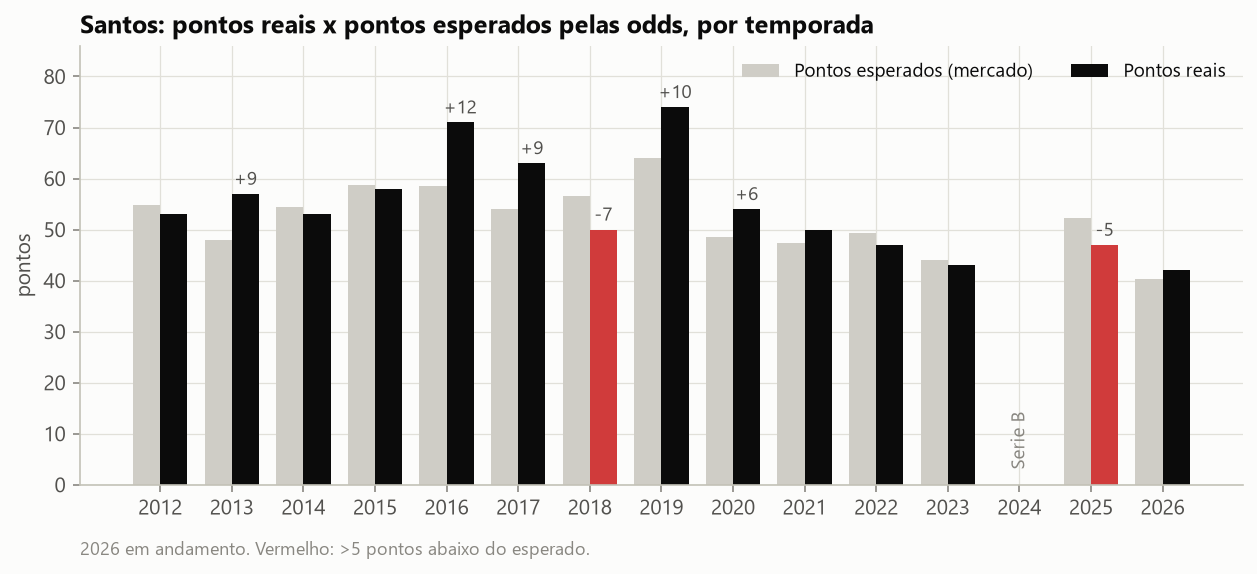

{'pontos_reais': 43,
 'xpts_mercado': 44.07159292141886,
 'p_pontos_ate_o_real': 0.4738,
 'p_rebaixamento_dadas_as_odds': 0.3949,
 'jogos_como_favorito': 2,
 'goleadas_sofridas_3_ou_mais': 7,
 'pre_temporada_dixon_coles': {'p_rebaixamento': 0.17170000000000002,
  'posicao_media': 11.36175,
  'pontos_esperados': 50.4201,
  'ranking_forca_pre_temporada': 11}}

In [7]:
s = ler("santos.json")
display(Image(config.FIGURAS / "santos_2023_simulacao.png"))
display(Image(config.FIGURAS / "santos_pontos_vs_xpts.png"))
{k: s[k] for k in ["pontos_reais", "xpts_mercado", "p_pontos_ate_o_real", "p_rebaixamento_dadas_as_odds",
                   "jogos_como_favorito", "goleadas_sofridas_3_ou_mais", "pre_temporada_dixon_coles"]}

**Nao foi azar.** O Santos fez 43 pontos e as odds de cada jogo esperavam 44,1 -- 47% das
temporadas simuladas terminam com 43 ou menos. Foi favorito em apenas 2 dos 38 jogos.

O que aconteceu foi uma **queda de nivel ao longo do ano**: antes da 1a rodada o Dixon-Coles via
um time de meio de tabela (11o em forca, 17% de risco de queda); jogo a jogo, o mercado foi
percebendo a piora, e o resultado final ficou exatamente onde a piora apontava.

## 4. Projecao 2026

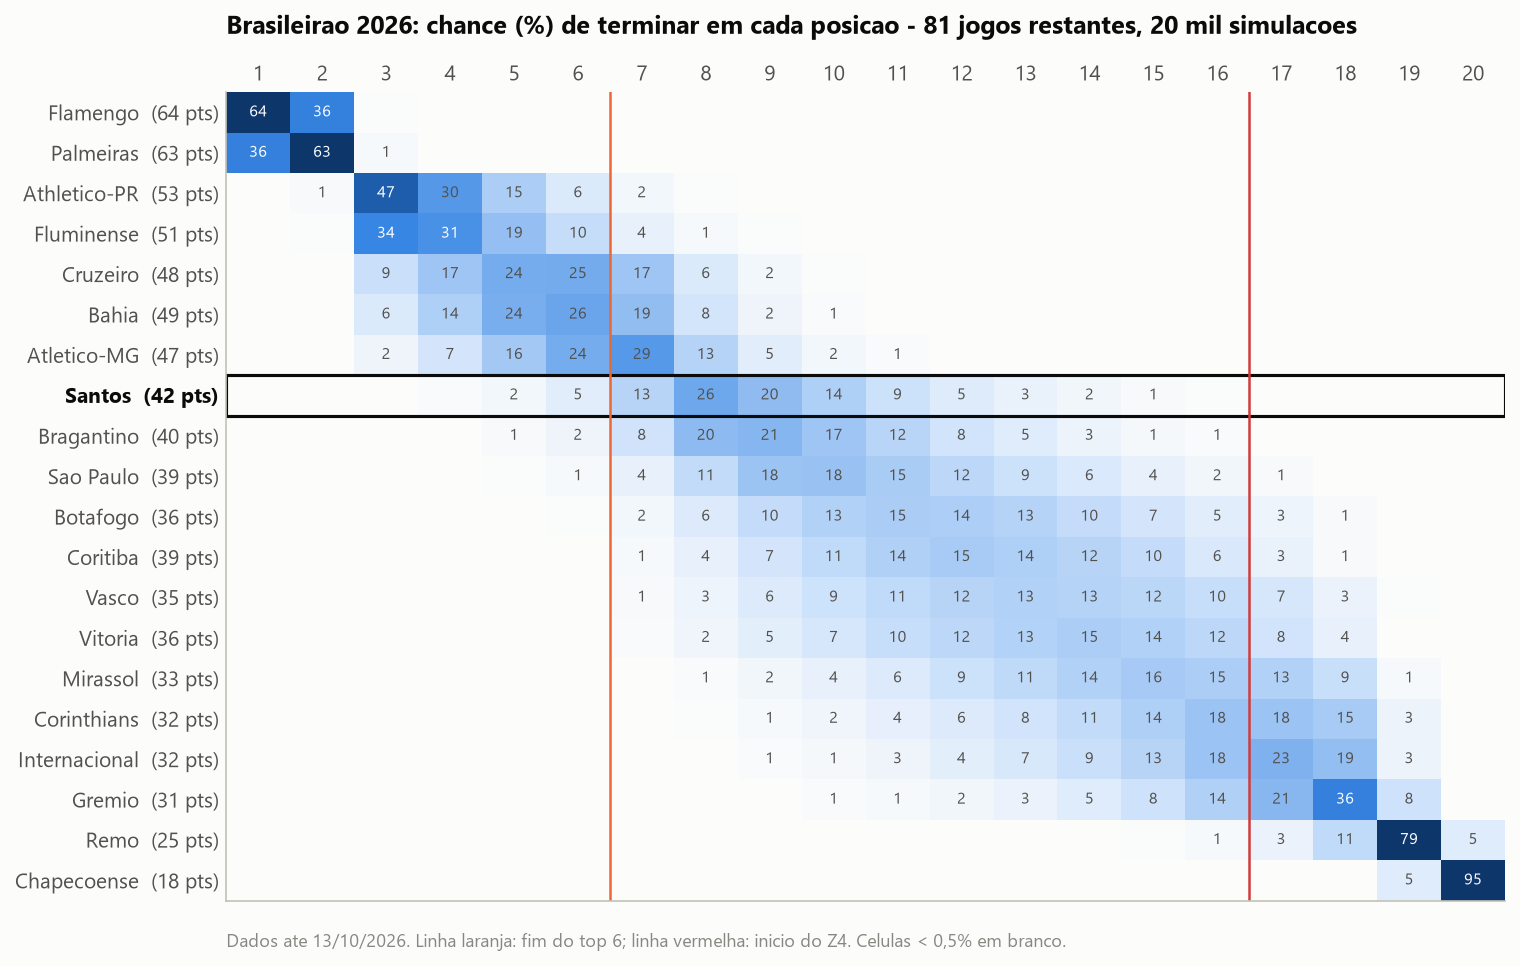

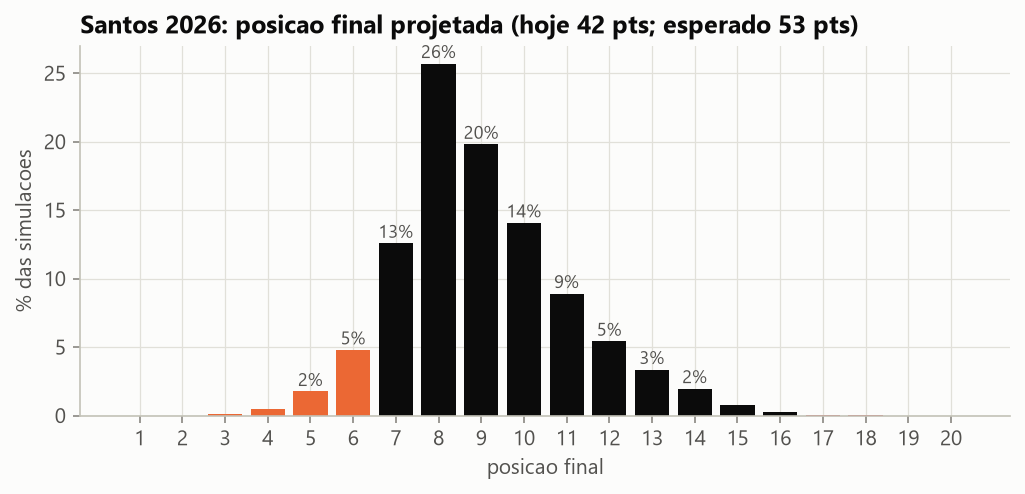

posicao              8.000
pontos              42.000
jogos               30.000
pontos_esperados    52.800
pontos_p05          47.000
pontos_p95          59.000
posicao_media        9.032
titulo               0.000
top6                 0.071
rebaixamento         0.001
dtype: float64

In [8]:
pr = ler("projecao.json")
display(Image(config.FIGURAS / "projecao_heatmap.png"))
display(Image(config.FIGURAS / "projecao_santos.png"))
pd.Series(pr["santos"]).round(3)

In [9]:
v = pr["validacao_no_passado"]
pd.DataFrame({e: {"brier": v[e]["brier"], "brier_ingenuo": v[e]["brier_ingenuo"],
                  ">=90%: casos": v[e]["acima_de_90pct"]["casos"],
                  ">=90%: aconteceu": v[e]["acima_de_90pct"]["aconteceu"],
                  "10-90%: prob media": v[e]["entre_10_e_90pct"]["prob_media"],
                  "10-90%: taxa real": v[e]["entre_10_e_90pct"]["taxa_real"]}
              for e in ["rebaixado", "top6", "campeao"]}).round(3)

,rebaixado,top6,campeao
brier,0.061,0.033,0.022
brier_ingenuo,0.160,0.210,0.047
>=90%: casos,16.000,36.000,3.000
>=90%: aconteceu,16.000,35.000,3.000
10-90%: prob media,0.456,0.520,0.421
10-90%: taxa real,0.452,0.559,0.308


A projecao foi refeita "com 300 jogos disputados" em 2017-2025: dos clubes com 10-90% de risco
de queda, o modelo dava em media 46% e 45% cairam. Todos os 16 com >= 90% cairam.

## Limitacoes

- So placares e odds: sem escalacao, lesoes, xG, calendario de copas. E por isso que o mercado ganha.
- Incerteza dos parametros fica de fora da simulacao (um ajuste so do DC), o que deixa as
  probabilidades um pouco confiantes demais nas pontas.
- Clube que sobe pela 1a vez herda a forca media dos 4 piores -- heuristica, nao estimativa.
- Desempate apos gols pro (confronto direto etc.) e sorteado.